# Итоговый проект по дисциплине «Обучение с подкреплением»
## Трек 1. Агент в классической среде «MountainCarContinuous-v0»
### Направления исследования:
Влияние уровня шума на качество работы обучения модели.
Агент выбирает уровень тяги по положению и скорости. Если мы добавим гауссовский шум к наблюдаемым агентом величинам, это должно повлиять на количество успехов.
### Метрика
1.	Доля эпизодов, которые завершились достижением цели.
2.	Суммарная награда
3.	Продолжительность эпизода
### План исследования
Учим агента SAC (Soft Actor-Critic) без шума с тремя значениями RANDOMSEED. Каждую итоговую политику оцениваем без обучения при α ∈ {0, 0.01, 0.05, 0.10}, по 20 эпизодов на условие и seed. Меняется только интенсивность шума наблюдений при оценке. Между условиями совпадают seed начальных состояний и базовые случайные последовательности шума; все параметры политики, динамика, награда и ограничение эпизода сохраняются. Всего 240 тестовых эпизодов. Seed оценки 10 000–10 019 не используются при обучении. Уровни шума и критерий не подбираем по результатам оценки.



## 1. Запуск и воспроизводимость
Файлы обучения, сырые результаты, графики, GIF и полный `pip freeze` сохраняются в `HW4_artifacts`. На повторном запуске используются контрольные точки только при совпадении конфигурации и версий основных библиотек. Для нового обучения установите `FORCE_RETRAIN = True`. Кривая обучения строится по завершённым обучающим эпизодам; тестовые эпизоды не участвуют в обновлении политики или выборе контрольной точки. Для CPU выделяется один поток PyTorch, время каждого обучения измеряется; лимит — 30 минут на seed.

In [1]:
# Раскомментируйте в новом окружении / Colab, затем перезапустите ядро при необходимости.
# %pip install "gymnasium==1.4.0" "stable-baselines3==2.9.2" "torch==2.15.0" "numpy==2.5.4" "pandas==3.1.1" "matplotlib==3.11.2" "pillow==11.3.0" "ipykernel>=6,<7"
import os
os.environ.setdefault("MPLBACKEND", "Agg")
import json
import subprocess
import sys
import time
from pathlib import Path
from importlib.metadata import version
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown, Image
from stable_baselines3 import SAC
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback

torch.set_num_threads(1)
ARTIFACTS = Path("HW4_artifacts")
ARTIFACTS.mkdir(exist_ok=True)
SEEDS = [42, 123, 777]
TIMESTEPS = 50_000
NOISE_LEVELS = [0.0, 0.01, 0.05, 0.10]
EVAL_SEEDS = list(range(10_000, 10_020))
FORCE_RETRAIN = False
VERSIONS = {p: version(p) for p in ["gymnasium", "stable-baselines3", "torch", "numpy", "pandas", "matplotlib", "pillow"]}
freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
(ARTIFACTS / "pip-freeze.txt").write_text(freeze, encoding="utf-8")
print("Python:", sys.version)
print(json.dumps(VERSIONS, indent=2))
print("Полный pip freeze: HW4_artifacts/pip-freeze.txt")

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
{
  "gymnasium": "1.4.0",
  "stable-baselines3": "2.9.2",
  "torch": "2.15.0",
  "numpy": "2.5.4",
  "pandas": "3.1.1",
  "matplotlib": "3.11.2",
  "pillow": "11.3.0"
}
Полный pip freeze: HW4_artifacts/pip-freeze.txt


## 2. Среда и алгоритм
Машина должна подняться на правый склон, набрав скорость раскачиванием. Наблюдение — положение $x\in[-1.2,0.6]$ и скорость $v\in[-0.07,0.07]$; действие — непрерывная тяга $a\in[-1,1]$. Цель: $x\geq0.45$ (порог скорости по умолчанию равен нулю). За достижение цели начисляется 100, на каждом шаге вычитается $0.1a^2$. Ограничение — 999 шагов. `terminated` означает достижение цели, `truncated` — исчерпание времени, поэтому обрыв по времени не считаем успехом.

SAC — алгоритм actor–critic для непрерывных действий, с буфером повторов и энтропийной регуляризацией. Сохраняем исходные гиперпараметры ноутбука: два скрытых слоя по 64 нейрона, γ=0.9999, learning rate=3·10⁻⁴, batch size=512, τ=0.01, коэффициент энтропии 0.1, gSDE для исследования. При оценке выбираем детерминированные действия. Гиперпараметры одинаковы во всех запусках.

In [2]:
env = gym.make("MountainCarContinuous-v0")
obs, _ = env.reset(seed=42)
print("Наблюдение:", obs)
print("Пространство наблюдений:", env.observation_space)
print("Пространство действий:", env.action_space)
print("Лимит шагов:", env.spec.max_episode_steps)
assert env.spec.max_episode_steps == 999
env.close()

Наблюдение: [-0.4452088  0.       ]
Пространство наблюдений: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Пространство действий: Box(-1.0, 1.0, (1,), float32)
Лимит шагов: 999


### 3. Шум наблюдений
Для добавления гаусовкого шума мы создадим собственный класс на основе gym.ObservationWrapper. Это позволит нам менять значения наблюдения для агента. Саму среду мы при это не меняем.

Класс принимает оригинальную среду env и уровень шума α. Определяем грацы измерений для обрезки , чтобы значения не превыщали границы допустимого. 

1. Метод RESET перезапускает среду в ачале нового эпизода, мы используем новый SEED на основе общего, чтобы они не повторяли дург-друга.
2. Метод OBSERVATION будет вызваться каждый раз , когда среда вернет наблюдения, после reset и step. Генеруется массив Ζ их нормального распределения, той же размерности что и исходные данные. Добавляем шум к истенным значениям. Обрезаем значения, чтобы они не вываливались за границы

$\tilde{s}_t = \mathrm{clip}(s_t + \alpha D z_t, s_{min}, s_{max})$, $z_t\sim\mathcal N(0,I)$, $D=\mathrm{diag}(1.8,0.14)$.


In [3]:
class NoisyObservationWrapper(gym.ObservationWrapper):
    def __init__(self, env, noise_level=0.0):
        super().__init__(env)
        if noise_level < 0:
            raise ValueError("noise_level должен быть неотрицательным")
        self.noise_level = float(noise_level)
        self.obs_low = self.observation_space.low.copy()
        self.obs_high = self.observation_space.high.copy()
        self.obs_range = self.obs_high - self.obs_low
        self.rng = np.random.default_rng()

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed + 100_000)
        return super().reset(seed=seed, options=options)

    def observation(self, observation):
        z = self.rng.standard_normal(size=observation.shape)
        return np.clip(observation + self.noise_level * self.obs_range * z,
                       self.obs_low, self.obs_high).astype(np.float32)

# Проверяем нулевой шум и повторяемость шума при одинаковом seed.
clean = gym.make("MountainCarContinuous-v0")
wrapped = NoisyObservationWrapper(gym.make("MountainCarContinuous-v0"), 0)
np.testing.assert_array_equal(clean.reset(seed=15)[0], wrapped.reset(seed=15)[0])
clean.close()
wrapped.close()
wrapped = NoisyObservationWrapper(gym.make("MountainCarContinuous-v0"), 0.05)
np.testing.assert_array_equal(wrapped.reset(seed=15)[0], wrapped.reset(seed=15)[0])
wrapped.close()
print("Проверки обёртки пройдены")

Проверки обёртки пройдены


## 4. Обучение без шума
Сохраняем все завершённые эпизоды через `Monitor` и время обучения. SB3 завершает пакет взаимодействий длиной 32 шага, поэтому фактический бюджет может немного превысить 50 000 (одинаково для всех seed). Контрольная точка берётся в конце фиксированного бюджета.

In [4]:
from copy import deepcopy

SAC_KWARGS = dict(
    learning_rate=3e-4, buffer_size=50_000, learning_starts=0,
    batch_size=512, gamma=0.9999, tau=0.01, train_freq=32,
    gradient_steps=32, ent_coef=0.1, use_sde=True,
    policy_kwargs={"net_arch": [64, 64], "log_std_init": -3.67},
)
CONFIG = {"env": "MountainCarContinuous-v0", "timesteps": TIMESTEPS,
          "parameters": SAC_KWARGS, "versions": VERSIONS, "threads": 1}

class TimeLimitCallback(BaseCallback):
    def _on_training_start(self):
        self.started = time.perf_counter()
    def _on_step(self):
        if time.perf_counter() - self.started > 1800:
            raise TimeoutError("Обучение превысило 30 минут; уменьшите бюджет и повторите все seed")
        return True

training_info = []
for seed in SEEDS:
    prefix = ARTIFACTS / f"sac_seed_{seed}"
    model_path = prefix.with_suffix(".zip")
    log_path = ARTIFACTS / f"train_{seed}.monitor.csv"
    meta_path = ARTIFACTS / f"train_{seed}.json"
    expected = {**CONFIG, "seed": seed}
    cached = json.loads(meta_path.read_text()) if meta_path.exists() else {}
    if (not FORCE_RETRAIN and model_path.exists() and log_path.exists()
            and cached.get("config") == expected):
        record = cached
        print(f"seed={seed}: загружены результаты предыдущего обучения", flush=True)
    else:
        env = Monitor(gym.make(CONFIG["env"]), filename=str(log_path))
        try:
            model = SAC("MlpPolicy", env, **deepcopy(SAC_KWARGS), seed=seed, verbose=0, device="cpu")
            started = time.perf_counter()
            model.learn(total_timesteps=TIMESTEPS, callback=TimeLimitCallback())
            elapsed = time.perf_counter() - started
            model.save(model_path)
            record = {"config": expected, "seconds": elapsed, "actual_steps": model.num_timesteps}
            meta_path.write_text(json.dumps(record, indent=2), encoding="utf-8")
            print(f"seed={seed}: {model.num_timesteps} шагов, {elapsed:.1f} с", flush=True)
        finally:
            env.close()
    training_info.append({"seed": seed, "steps": record["actual_steps"],
                          "training_minutes": record["seconds"] / 60})
training_df = pd.DataFrame(training_info)
training_df.to_csv(ARTIFACTS / "training_times.csv", index=False)
display(training_df.round(3))

seed=42: загружены результаты предыдущего обучения
seed=123: загружены результаты предыдущего обучения
seed=777: загружены результаты предыдущего обучения


,seed,steps,training_minutes
0,42,50016,4.618
1,123,50016,4.991
2,777,50016,5.002


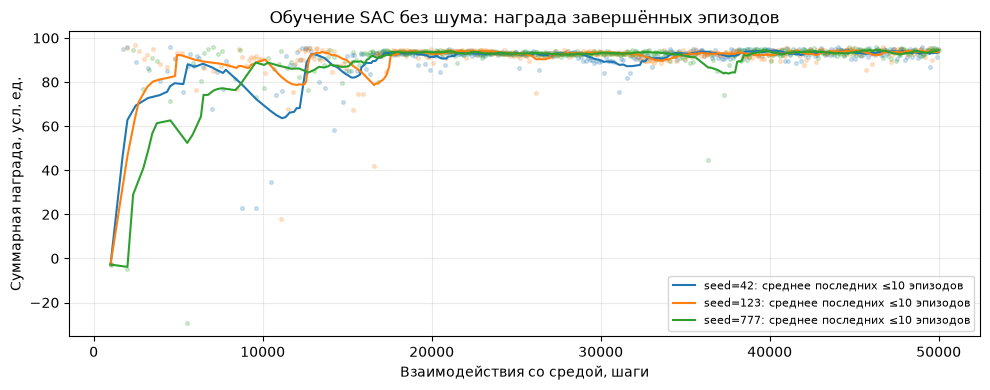

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
for seed in SEEDS:
    log = pd.read_csv(ARTIFACTS / f"train_{seed}.monitor.csv", comment="#")
    steps = log["l"].cumsum()
    smooth = log["r"].rolling(10, min_periods=1).mean()
    line, = ax.plot(steps, smooth, label=f"seed={seed}: среднее последних ≤10 эпизодов")
    ax.scatter(steps, log["r"], s=7, alpha=0.2, color=line.get_color())
ax.set(title="Обучение SAC без шума: награда завершённых эпизодов",
       xlabel="Взаимодействия со средой, шаги", ylabel="Суммарная награда, усл. ед.")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(ARTIFACTS / "learning_curves.png", dpi=150)
plt.show()

Точки показывают отдельные обучающие эпизоды, линии — скользящее среднее не более чем по 10 последним эпизодам **внутри каждого seed**, без усреднения разных seed. Различия линий показывают вариативность обучения; итоговое качество проверяем отдельно на отложенных начальных состояниях.

## 5. Итоговая оценка без обучения
Для каждого seed обучения и уровня шума сохраняем все 20 эпизодов, а не только их среднее. Веса и политики модели заморожены. Энергия считается по фактически поданным действиям; ограничение пространства действий дополнительно проверяется.

In [6]:
def evaluate_agent(model, noise_level, train_seed, episode_seeds=EVAL_SEEDS):
    env = NoisyObservationWrapper(gym.make("MountainCarContinuous-v0"), noise_level)
    rows = []
    try:
        for episode_seed in episode_seeds:
            obs, _ = env.reset(seed=episode_seed)
            total_reward, energy, steps = 0.0, 0.0, 0
            terminated = truncated = False
            while not (terminated or truncated):
                action, _ = model.predict(obs, deterministic=True)
                assert env.action_space.contains(action)
                obs, reward, terminated, truncated, _ = env.step(action)
                total_reward += float(reward)
                energy += float(np.square(action.astype(np.float64)).sum())
                steps += 1
            rows.append(dict(train_seed=train_seed, noise_level=noise_level,
                             episode_seed=episode_seed, success=int(terminated),
                             reward=total_reward, length=steps, energy=energy,
                             truncated=bool(truncated)))
    finally:
        env.close()
    return pd.DataFrame(rows)

parts = []
for seed in SEEDS:
    model = SAC.load(ARTIFACTS / f"sac_seed_{seed}.zip", device="cpu")
    for alpha in NOISE_LEVELS:
        part = evaluate_agent(model, alpha, seed)
        parts.append(part)
        print(f"seed={seed}, α={alpha:.2f}: успех {part.success.mean():.0%}, награда {part.reward.mean():.2f}", flush=True)
episodes = pd.concat(parts, ignore_index=True)
episodes.to_csv(ARTIFACTS / "evaluation_episodes.csv", index=False)
assert len(episodes) == len(SEEDS) * len(NOISE_LEVELS) * len(EVAL_SEEDS)
assert episodes.groupby(["train_seed", "noise_level"]).size().eq(20).all()
assert episodes["length"].between(1, 999).all()
assert np.allclose(episodes.reward, 100 * episodes.success - 0.1 * episodes.energy, atol=1e-4)
print("Проверены число эпизодов, длины и соответствие награды энергии и успеху")

seed=42, α=0.00: успех 100%, награда 94.58
seed=42, α=0.01: успех 100%, награда 94.28
seed=42, α=0.05: успех 100%, награда 93.90
seed=42, α=0.10: успех 100%, награда 92.31
seed=123, α=0.00: успех 100%, награда 94.48
seed=123, α=0.01: успех 100%, награда 94.47
seed=123, α=0.05: успех 100%, награда 93.45
seed=123, α=0.10: успех 100%, награда 92.63
seed=777, α=0.00: успех 100%, награда 94.68
seed=777, α=0.01: успех 100%, награда 94.68
seed=777, α=0.05: успех 100%, награда 94.31
seed=777, α=0.10: успех 100%, награда 91.40
Проверены число эпизодов, длины и соответствие награды энергии и успеху


In [7]:
METRICS = ["success", "reward", "length", "energy"]
per_seed = episodes.groupby(["train_seed", "noise_level"])[METRICS].mean().reset_index()
per_seed.to_csv(ARTIFACTS / "evaluation_per_seed.csv", index=False)
summary = per_seed.groupby("noise_level")[METRICS].agg(["mean", "std"])
summary.to_csv(ARTIFACTS / "evaluation_summary.csv")
table = pd.DataFrame(index=summary.index)
table.index.name = "α (доля диапазона)"
for metric, label, scale in [
    ("success", "Успех, %", 100), ("reward", "Награда, усл. ед.", 1),
    ("length", "Длина, шаги", 1), ("energy", "Σ a², усл. ед.", 1)]:
    table[label] = [f"{m*scale:.2f} ± {s*scale:.2f}" for m, s in
                    zip(summary[(metric, "mean")], summary[(metric, "std")])]
display(table)
print("Среднее ± выборочное SD по 3 seed обучения; каждый seed оценён на 20 эпизодах в условии.")
display(per_seed.round(3))

,"Успех, %","Награда, усл. ед.","Длина, шаги","Σ a², усл. ед."
α (доля диапазона),,,,
0.00,100.00 ± 0.00,94.58 ± 0.10,88.80 ± 6.56,54.21 ± 1.02
0.01,100.00 ± 0.00,94.48 ± 0.20,90.28 ± 6.74,55.23 ± 2.01
0.05,100.00 ± 0.00,93.89 ± 0.43,99.12 ± 2.01,61.10 ± 4.31
0.10,100.00 ± 0.00,92.12 ± 0.64,129.57 ± 18.70,78.85 ± 6.36


Среднее ± выборочное SD по 3 seed обучения; каждый seed оценён на 20 эпизодах в условии.


,train_seed,noise_level,success,reward,length,energy
0,42,0.00,1.0,94.578,87.80,54.219
1,42,0.01,1.0,94.281,91.70,57.187
2,42,0.05,1.0,93.902,97.20,60.982
3,42,0.10,1.0,92.308,122.60,76.915
4,123,0.00,1.0,94.477,82.80,55.230
5,123,0.01,1.0,94.465,82.95,55.348
6,123,0.05,1.0,93.453,98.95,65.468
7,123,0.10,1.0,92.633,115.35,73.670
8,777,0.00,1.0,94.681,95.80,53.194
9,777,0.01,1.0,94.684,96.20,53.163


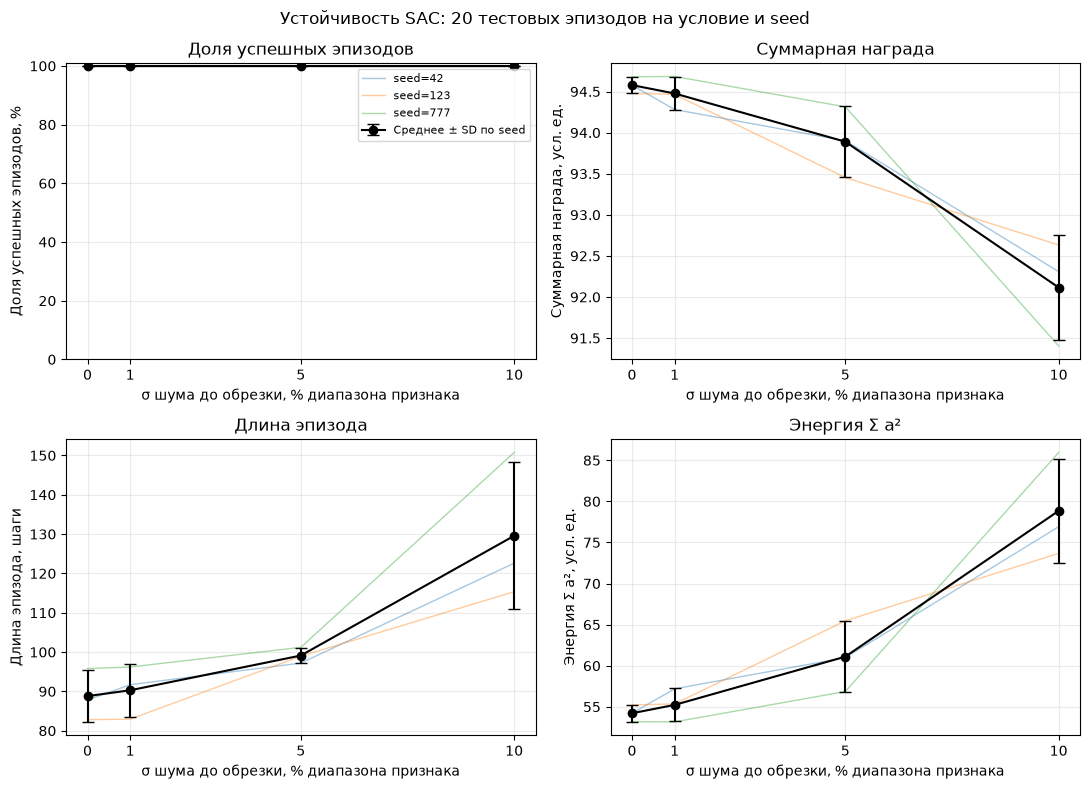

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, metric, label, scale in zip(
    axes.flat, METRICS,
    ["Доля успешных эпизодов, %", "Суммарная награда, усл. ед.",
     "Длина эпизода, шаги", "Энергия Σ a², усл. ед."], [100, 1, 1, 1]):
    for i, seed in enumerate(SEEDS):
        data = per_seed[per_seed.train_seed == seed].sort_values("noise_level")
        ax.plot(data.noise_level * 100, data[metric] * scale,
                alpha=0.4, linewidth=1, label=f"seed={seed}")
    ax.errorbar(summary.index.to_numpy() * 100, summary[(metric, "mean")] * scale,
                yerr=summary[(metric, "std")] * scale, fmt="o-", color="black",
                capsize=4, label="Среднее ± SD по seed")
    ax.set(xlabel="σ шума до обрезки, % диапазона признака", ylabel=label, title=label.split(",")[0])
    ax.set_xticks(np.array(NOISE_LEVELS) * 100)
    ax.grid(alpha=0.25)
axes[0, 0].set_ylim(0, 101)
axes[0, 0].set_yticks(np.arange(0, 101, 20))
axes[0, 0].legend(fontsize=8)
fig.suptitle("Устойчивость SAC: 20 тестовых эпизодов на условие и seed")
fig.tight_layout()
fig.savefig(ARTIFACTS / "noise_comparison.png", dpi=150)
plt.show()

Столбики ошибок — выборочное стандартное отклонение **средних по трём seed обучения**, а не доверительный интервал. Тонкие линии позволяют увидеть каждый запуск. Эпизоды одного агента зависимы через общие параметры политики, поэтому не рассматриваем все 60 эпизодов как 60 независимых обучений. При трёх seed оценка разброса сама по себе неточна.

## 6. Парное сравнение и ответ на исследовательский вопрос
Вычитаем базовый успех того же seed из результата при шуме. Отрицательная разность означает ухудшение; порог гипотезы — −20 п. п. Для гипотезы используем заранее выбранное сравнение α=0.10 с α=0; остальные уровни уточняют, где появляется заметное снижение.

In [9]:
paired = per_seed.pivot(index="train_seed", columns="noise_level", values="success")
delta = (paired.subtract(paired[0.0], axis=0) * 100)
display(delta.rename_axis(columns="α: изменение успеха к базе, п. п."))
delta.to_csv(ARTIFACTS / "paired_success_delta_pp.csv")
mean_delta = delta.mean()
observed_drop = -float(mean_delta.loc[0.10])
qualifying = [a for a in NOISE_LEVELS if a > 0 and -mean_delta.loc[a] >= 20 - 1e-9]
threshold_text = (f"Первый из проверенных уровней с падением ≥20 п. п.: **α={min(qualifying):.2f}**. "
                  "Точный порог между уровнями этой сеткой не определён."
                  if qualifying else "На проверенной сетке уровней падение ≥20 п. п. не обнаружено.")
verdict = ("подтверждается описательно в этом эксперименте" if observed_drop >= 20 - 1e-9
           else "не подтверждается в этом эксперименте")
base_success = summary.loc[0.0, ("success", "mean")] * 100
noisy_success = summary.loc[0.10, ("success", "mean")] * 100
base_reward = summary.loc[0.0, ("reward", "mean")]
noisy_reward = summary.loc[0.10, ("reward", "mean")]
base_energy = summary.loc[0.0, ("energy", "mean")]
noisy_energy = summary.loc[0.10, ("energy", "mean")]
base_length = summary.loc[0.0, ("length", "mean")]
noisy_length = summary.loc[0.10, ("length", "mean")]
report = f"""### Вывод по отложенным данным
Без шума средняя доля успехов **{base_success:.1f}%**, при α=0.10 — **{noisy_success:.1f}%**.
Изменение (шум − база): **{mean_delta.loc[0.10]:+.1f} п. п.**
Основная гипотеза **{verdict}**. Это проверка заранее заданного размера эффекта по выборочным средним, а не утверждение статистической значимости.

{threshold_text}

Средняя награда меняется с **{base_reward:.2f}** до **{noisy_reward:.2f}**,
энергия — с **{base_energy:.2f}** до **{noisy_energy:.2f}**
(изменение **{(noisy_energy/base_energy-1)*100:+.1f}%**).
Средняя длина эпизода меняется с **{base_length:.2f}** до **{noisy_length:.2f}** шага
(изменение **{(noisy_length/base_length-1)*100:+.1f}%**).
Разность наград согласуется с формулой среды: 100 × изменение доли успехов − 0.1 × изменение энергии.
Снижение награды возможно и при сохранении успеха, если агент тратит больше действий на раскачивание.
Более длинные эпизоды и колебания тяги согласуются с ошибками оценки скорости и положения;
это возможное объяснение, а не отдельная проверка причинного механизма.
"""
display(Markdown(report))
(ARTIFACTS / "conclusion.md").write_text(report, encoding="utf-8")

"α: изменение успеха к базе, п. п.",0.00,0.01,0.05,0.10
train_seed,,,,
42,0.0,0.0,0.0,0.0
123,0.0,0.0,0.0,0.0
777,0.0,0.0,0.0,0.0


### Вывод по отложенным данным
Без шума средняя доля успехов **100.0%**, при α=0.10 — **100.0%**.
Изменение (шум − база): **+0.0 п. п.**
Основная гипотеза **не подтверждается в этом эксперименте**. Это проверка заранее заданного размера эффекта по выборочным средним, а не утверждение статистической значимости.

На проверенной сетке уровней падение ≥20 п. п. не обнаружено.

Средняя награда меняется с **94.58** до **92.12**,
энергия — с **54.21** до **78.85**
(изменение **+45.4%**).
Средняя длина эпизода меняется с **88.80** до **129.57** шага
(изменение **+45.9%**).
Разность наград согласуется с формулой среды: 100 × изменение доли успехов − 0.1 × изменение энергии.
Снижение награды возможно и при сохранении успеха, если агент тратит больше действий на раскачивание.
Более длинные эпизоды и колебания тяги согласуются с ошибками оценки скорости и положения;
это возможное объяснение, а не отдельная проверка причинного механизма.


939

## 7. Анимация поведения итогового агента
Показываем заранее выбранный seed обучения **42** и тестовый seed **10 000**, без выбора удачного эпизода. Слева чистые наблюдения, справа α=0.10; начальное физическое состояние совпадает. Это анимация реальных состояний среды: координаты берутся из `env.unwrapped.state`, профиль склона соответствует MountainCar. Изображение строится Matplotlib, поэтому установка `pygame` для рендера не требуется. Кадр показывается каждые 5 шагов, 6 кадров/с (примерно шестикратное ускорение относительно 30 шагов/с); последний кадр завершившегося эпизода удерживается. Анимация иллюстрирует поведение, но выводы сделаны по полной тестовой выборке.

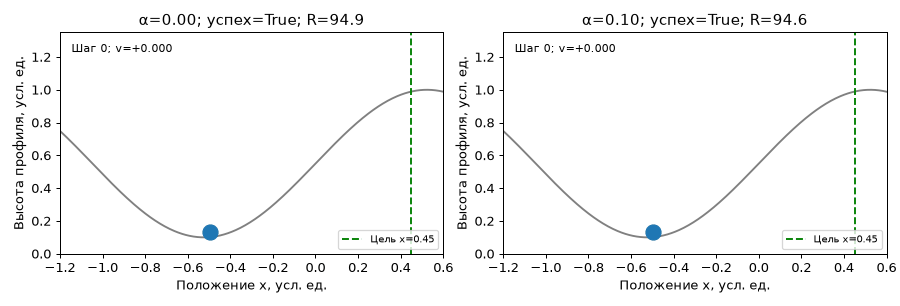

In [10]:
from matplotlib.animation import FuncAnimation, PillowWriter

def rollout_for_animation(model, alpha, episode_seed=10_000):
    env = NoisyObservationWrapper(gym.make("MountainCarContinuous-v0"), alpha)
    states = []
    reward_sum = 0.0
    try:
        obs, _ = env.reset(seed=episode_seed)
        states.append(env.unwrapped.state.copy())
        done = False
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, _ = env.step(action)
            states.append(env.unwrapped.state.copy())
            reward_sum += reward
            done = terminated or truncated
        return np.asarray(states), float(reward_sum), bool(terminated)
    finally:
        env.close()

model = SAC.load(ARTIFACTS / "sac_seed_42.zip", device="cpu")
trajectories = [rollout_for_animation(model, alpha) for alpha in [0.0, 0.10]]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
artists = []
x = np.linspace(-1.2, 0.6, 400)
for ax, alpha, (states, reward, success) in zip(axes, [0.0, 0.10], trajectories):
    ax.plot(x, np.sin(3*x) * 0.45 + 0.55, color="gray")
    ax.axvline(0.45, color="green", linestyle="--", label="Цель x=0.45")
    car, = ax.plot([], [], "o", markersize=12, color="tab:blue")
    text = ax.text(0.03, 0.95, "", transform=ax.transAxes, va="top", fontsize=9)
    ax.set(xlim=(-1.2, 0.6), ylim=(0, 1.35), xlabel="Положение x, усл. ед.",
           ylabel="Высота профиля, усл. ед.",
           title=f"α={alpha:.2f}; успех={success}; R={reward:.1f}")
    ax.legend(loc="lower right", fontsize=8)
    artists.append((car, text))
fig.tight_layout()
max_steps = max(len(t[0]) for t in trajectories) - 1
frame_steps = list(range(0, max_steps + 1, 5))
if frame_steps[-1] != max_steps:
    frame_steps.append(max_steps)

def update(step):
    for (car, text), (states, _, _) in zip(artists, trajectories):
        k = min(step, len(states)-1)
        position, velocity = states[k]
        car.set_data([position], [np.sin(3*position)*0.45 + 0.58])
        text.set_text(f"Шаг {k}; v={velocity:+.3f}")
    return [artist for pair in artists for artist in pair]

animation = FuncAnimation(fig, update, frames=frame_steps, interval=1000/6, blit=False)
gif_path = ARTIFACTS / "sac_behavior.gif"
animation.save(gif_path, writer=PillowWriter(fps=6), dpi=90)
plt.close(fig)
display(Image(data=gif_path.read_bytes(), format="gif"))

## 8. Ограничения и дальнейшая проверка
- Три seed обучения и 20 эпизодов на условие дают лишь предварительную оценку. Нулевой разброс успехов не доказывает отсутствие риска ошибок; редкие неудачи могут не попасть в выборку. Парные начальные состояния делают сравнение условий точнее, но не заменяют новые обучения.
- Проверена одна среда, одна конфигурация SAC и один бюджет. Слабое исходное обучение может скрывать ухудшение из-за шума; на кривых и в таблице нужно учитывать результат каждого seed отдельно.
- Изучен только независимый гауссовский шум с обрезкой. Постоянное смещение датчика, коррелированный шум, задержки наблюдений и изменение физики могут дать другой результат. Значение 10% диапазона — это разные абсолютные ошибки в двух признаках.
- Успех — дискретная метрика; награда, длина и энергия могут ухудшиться раньше. Энергия зависит и от интенсивности управления, и от длительности эпизода, поэтому её рост сам по себе не означает более сильную тягу на каждом шаге.
- Следующий эксперимент: проверить больше seed и расширить диапазон шума выше 10% на новой тестовой выборке. Если граница снижения обнаружится, уплотнить сетку вокруг неё. Отдельным исследованием можно сравнить обучение без шума с обучением с шумом, сохранив остальные параметры. Текущие данные не доказывают, что такое обучение повысит устойчивость.

Все численные выводы выше используют только итоговые тестовые эпизоды без обучения. `evaluation_episodes.csv` содержит исходные данные для независимого пересчёта таблиц и графиков; `pip-freeze.txt` — полное окружение выполненного запуска.

В выполненном запуске все 240 эпизодов успешны: метрика успеха достигла потолка. При α=0.10 средняя длина эпизода выросла примерно на 45.9%, энергия — на 45.4%, а награда снизилась примерно на 2.46. Таким образом, на выбранной сетке агент устойчив по достижению цели, но менее эффективен по времени и затратам управления. Возможное объяснение сохранения успеха — корректирующая обратная связь и большой запас до лимита 999 шагов; проверка этого механизма потребует отдельного эксперимента. Эти выводы относятся к полученной выборке, а не гарантируют успех при любом шуме до 10%.